# Visual Modality: Training & Evaluation

Sequence model (bi-LSTM / GRU) on the cached `(T, D)` visual features from the EDA pipeline. Real data only. All logic lives in `src/training/visual/`.

| Stage | Class | Module |
|---|---|---|
| Load cached features | `CachedFeatureLoader`, `FeatureSelector`, `SpeakerParser` | `dataset.py` |
| Speaker-disjoint split | `SpeakerSplitter` | `splits.py` |
| Normalise + torch dataset | `Standardizer`, `VisualSequenceDataset` | `dataset.py` |
| Model | `RNNClassifier` (`rnn_type="lstm"\|"gru"`) | `model.py` |
| Training | `Trainer` | `trainer.py` |
| Evaluation | `Evaluator` | `evaluator.py` |
| One full run / seed sweep | `Experiment` | `experiment.py` |

Switch LSTM <-> GRU, pooling, or feature subsets (ablations) only in the config cell.

In [77]:
import os, sys
import numpy as np
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)
os.environ["LIBGL_ALWAYS_SOFTWARE"] = "1"

import pandas as pd
from IPython.display import display

from src.common.constants import OPENFACE_BIN
from src.extractors.visual.visual_feature_extractor import VisualFeatureExtractor
from notebooks.eda.visual import (
    EDAConfig, HFDatasetLoader, VideoCatalog, OpenFaceTableStore, SceneDetector,
    QualityAuditor, QualityThresholds, FeatureStore,
)
from src.training.visual import (
    TrainConfig, CachedFeatureLoader, FeatureSelector, SpeakerParser, SpeakerSplitter,
    Experiment, TrainingPlots, EvalPlots, Evaluator,
)

## Config

In [78]:
eda_cfg = EDAConfig(data_dir="../data", openface_bin=OPENFACE_BIN, device="cuda")   # same settings as the EDA notebook

cfg = TrainConfig(
    rnn_type="gru",            # "lstm" | "gru"
    hidden_dim=128, num_layers=2, bidirectional=False, pooling="attention",
    use_quality_gate=True,     # True = only keep videos whose scenes all pass the Stage-3 gate
    include_prefixes=None,      # e.g. ("au_", "gaze_")
    exclude_prefixes=None,      # e.g. ("emo_",) to ablate emotion probabilities
    seed=42,
)
os.makedirs(cfg.output_dir, exist_ok=True)
print(cfg)

TrainConfig(use_quality_gate=True, include_prefixes=None, exclude_prefixes=None, val_frac=0.15, test_frac=0.15, batch_size=32, rnn_type='gru', hidden_dim=128, num_layers=2, bidirectional=False, dropout=0.3, pooling='attention', lr=0.001, weight_decay=0.01, epochs=100, patience=14, grad_clip=1.0, class_weighted_loss=True, noise_std=0.05, feature_dropout=0.1, seed=42, device='cuda', output_dir='../outputs/visual_training', num_workers=0)


## Data: cached OpenFace features
Reuses the EDA caches (`openface_cache`, `feature_cache`); only videos missing from them are computed.

In [79]:
MAX_VIDEOS = 9999999

loader = HFDatasetLoader(eda_cfg.hf_repo_id, eda_cfg.data_dir, folders=eda_cfg.hf_folders)
# loader.download()
catalog = VideoCatalog(eda_cfg.data_dir)
meta_df = catalog.build(loader.local_video_paths())

meta_df = meta_df.sample(n=min(MAX_VIDEOS, len(meta_df)), random_state=cfg.seed).reset_index(drop=True)

extractor = VisualFeatureExtractor(openface_bin_path=eda_cfg.openface_bin, device=eda_cfg.device)
tables = OpenFaceTableStore(extractor, eda_cfg.openface_cache_dir, workers=eda_cfg.openface_workers)
tables.ensure(meta_df)
features = FeatureStore(extractor, tables, eda_cfg.feature_cache_dir, target_t=eda_cfg.target_t)

Reading video metadata:   0%|          | 0/1573 [00:00<?, ?it/s]

Invalid model-index. Not loading eval results into CardData.
Invalid model-index. Not loading eval results into CardData.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[openface] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s


In [80]:
quality_df = None
if cfg.use_quality_gate:
    scenes, _ = SceneDetector(
        eda_cfg.scene_cache_dir, method=eda_cfg.scene_method, threshold=eda_cfg.scene_threshold,
        min_scene_len=eda_cfg.scene_min_len, frame_skip=eda_cfg.scene_frame_skip,
        workers=eda_cfg.scene_workers, jump_mm=eda_cfg.pose_jump_mm).ensure(meta_df, tables)
    quality_df, _ = QualityAuditor(QualityThresholds(
        eda_cfg.conf_thresh, eda_cfg.jitter_thresh, eda_cfg.max_dropout_pct)).audit(meta_df, tables, scenes)

feature_loader = CachedFeatureLoader(features, SpeakerParser())   # pass SpeakerParser(fn) if the truth/ layout differs
data = feature_loader.load(meta_df, quality_df, FeatureSelector(cfg.include_prefixes, cfg.exclude_prefixes))
display(data.describe())
print(f"{data.input_dim} features:", data.feature_names)

[scenes[content]] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.2s


Quality audit:   0%|          | 0/1573 [00:00<?, ?it/s]

[quality audit] 1573 videos | 0 cached | 1573 computed | 0 failed | 4.3s
[features] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s
[features] 1573 videos | 1573 cached | 0 computed | 0 failed | 0.0s


Loading tensors:   0%|          | 0/1573 [00:00<?, ?it/s]

dropping 0 videos with Unknown label
quality gate removes 380 videos


,videos,speakers,truth,lie,T,D
0,1193,196,538,655,64,58


58 features: ['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r', 'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r', 'AU25_r', 'AU26_r', 'AU45_r', 'AU01_c', 'AU02_c', 'AU04_c', 'AU05_c', 'AU06_c', 'AU07_c', 'AU09_c', 'AU10_c', 'AU12_c', 'AU14_c', 'AU15_c', 'AU17_c', 'AU20_c', 'AU23_c', 'AU25_c', 'AU26_c', 'AU28_c', 'AU45_c', 'pose_Tx', 'pose_Ty', 'pose_Tz', 'pose_Rx', 'pose_Ry', 'pose_Rz', 'gaze_0_x', 'gaze_0_y', 'gaze_0_z', 'gaze_1_x', 'gaze_1_y', 'gaze_1_z', 'gaze_angle_x', 'gaze_angle_y', 'valid', 'confidence', 'emo_Anger', 'emo_Disgust', 'emo_Fear', 'emo_Happiness', 'emo_Neutral', 'emo_Sadness', 'emo_Surprise']


## Split preview (speaker-disjoint, label-stratified)

In [81]:
splits = SpeakerSplitter(cfg.val_frac, cfg.test_frac, cfg.seed).split(data)
display(SpeakerSplitter.summary(data, splits))

,videos,speakers,truth,lie,lie_ratio
split,,,,,
train,852,141,383,469,0.550
val,173,24,78,95,0.549
test,168,31,77,91,0.542


## Train

ep   1 | loss 0.695/0.690 | acc 0.498/0.445 | val F1 0.308 (best 0.308 @ 1)
ep   5 | loss 0.639/0.718 | acc 0.640/0.538 | val F1 0.497 (best 0.520 @ 2)
ep  10 | loss 0.544/0.920 | acc 0.710/0.497 | val F1 0.485 (best 0.520 @ 2)
ep  15 | loss 0.452/1.121 | acc 0.775/0.491 | val F1 0.479 (best 0.520 @ 2)
early stop at epoch 16
best epoch 2 | val F1 0.520 | 3s


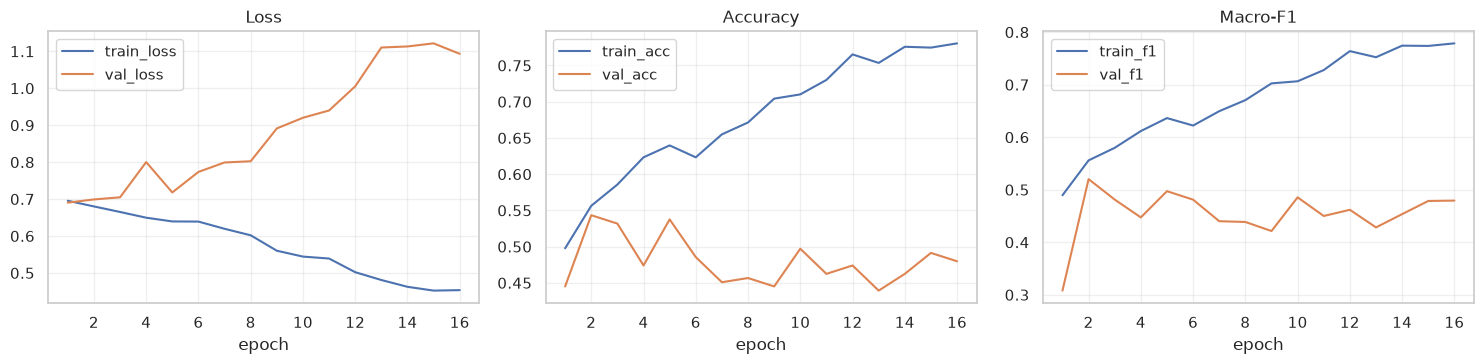

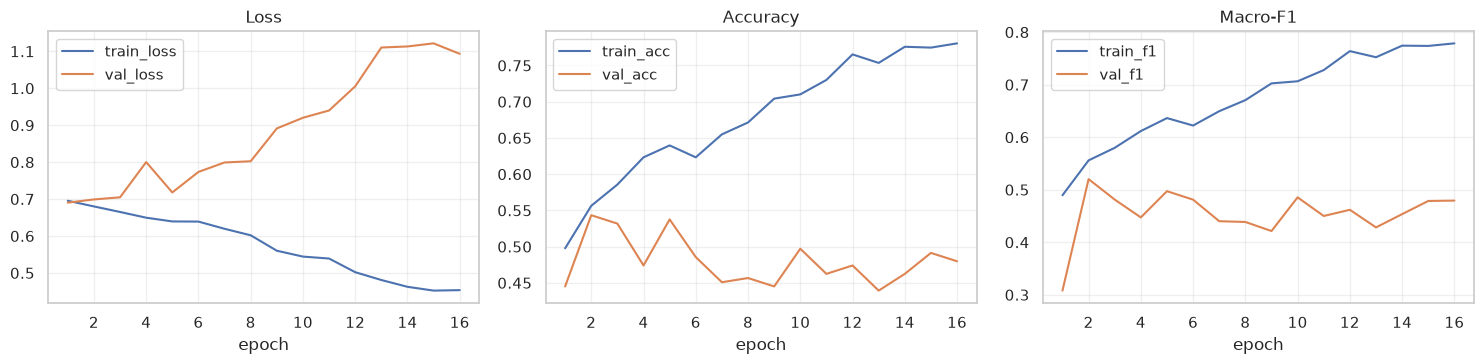

In [82]:
exp = Experiment(cfg)
result = exp.run(data)
TrainingPlots.curves(result.history)

## Evaluate
Train / val / test, with per-video predictions saved to CSV.

,accuracy,balanced_acc,f1_macro,precision_lie,recall_lie,auc
train,0.6279,0.6216,0.6220,0.6551,0.6844,0.6575
val,0.5434,0.5269,0.5202,0.5690,0.6947,0.5336
test,0.4821,0.4750,0.4739,0.5204,0.5604,0.4989


,pred Truth,pred Lie
true Truth,28,50
true Lie,29,66


,pred Truth,pred Lie
true Truth,30,47
true Lie,40,51


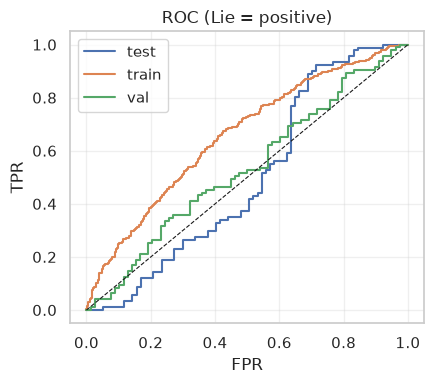

In [83]:
display(result.metrics)
for split in ["val", "test"]:
    display(Evaluator.confusion(result.predictions, split))
EvalPlots.roc(result.predictions)

result.predictions.to_csv(f"{cfg.output_dir}/predictions_{cfg.rnn_type}_seed{result.seed}.csv", index=False)
result.metrics.to_csv(f"{cfg.output_dir}/metrics_{cfg.rnn_type}_seed{result.seed}.csv")

In [84]:
display(Evaluator.per_speaker(result.predictions, "test"))
display(result.predictions.query("split == 'test' and not correct").head(20))

,videos,accuracy
speaker,,
Chris Addison,2,0.000
Catherine,3,0.000
John Barrowman,3,0.000
Greg Rutherford,1,0.000
Ronni Ancona,1,0.000
Richard E Grant,3,0.000
Randy_Mills,1,0.000
Miles,5,0.000
Wendy Richard,1,0.000


,split,video_id,speaker,label,pred,p_lie,correct
1026,test,deception/DOLOS/Male/Lee Mack/BRI_WILTY_EP61_l...,Lee Mack,Lie,Truth,0.459729,False
1031,test,truth/DOLOS/Male/John Barrowman/LS_WILTY_EP2_t...,John Barrowman,Truth,Lie,0.606571,False
1033,test,truth/DOLOS/Male/Lee Mack/AN_WILTY_EP25_truth6...,Lee Mack,Truth,Lie,0.577909,False
1035,test,deception/DOLOS/Male/Rod/YW_WILTY_EP46_lie1.mp4,Rod,Lie,Truth,0.467922,False
1040,test,deception/DOLOS/Female/Sarah Millican/BRI_WILT...,Sarah Millican,Lie,Truth,0.473723,False
1047,test,truth/DOLOS/Male/Lee Mack/LS_WILTY_EP4_truth6.mp4,Lee Mack,Truth,Lie,0.616665,False
1048,test,truth/DOLOS/Male/Bradley/YW_WILTY_EP54_truth7.mp4,Bradley,Truth,Lie,0.542198,False
1051,test,deception/DOLOS/Female/Nina/YW_WILTY_EP44_lie6...,Nina,Lie,Truth,0.389273,False
1052,test,deception/DOLOS/Male/Chris Addison/SB_WILTY_EP...,Chris Addison,Lie,Truth,0.394159,False
1053,test,deception/DOLOS/Female/Sarah Millican/SB_WILTY...,Sarah Millican,Lie,Truth,0.476924,False


## Robustness: repeat over seeds
Each seed draws a new speaker split, so this measures split variance as well as init variance. Single-split test accuracy on a small dataset is noisy.


=== seed 0 ===
ep   1 | loss 0.693/0.709 | acc 0.501/0.432 | val F1 0.429 (best 0.429 @ 1)
ep   5 | loss 0.645/0.758 | acc 0.611/0.497 | val F1 0.488 (best 0.488 @ 5)
ep  10 | loss 0.555/1.002 | acc 0.706/0.426 | val F1 0.424 (best 0.488 @ 5)
ep  15 | loss 0.452/1.414 | acc 0.794/0.497 | val F1 0.467 (best 0.490 @ 13)
ep  20 | loss 0.399/1.497 | acc 0.825/0.485 | val F1 0.478 (best 0.495 @ 19)
ep  25 | loss 0.314/1.979 | acc 0.851/0.456 | val F1 0.447 (best 0.495 @ 19)
ep  30 | loss 0.270/1.994 | acc 0.884/0.491 | val F1 0.476 (best 0.495 @ 19)
early stop at epoch 33
best epoch 19 | val F1 0.495 | 6s

=== seed 1 ===
ep   1 | loss 0.693/0.689 | acc 0.561/0.468 | val F1 0.409 (best 0.409 @ 1)
ep   5 | loss 0.646/0.694 | acc 0.617/0.550 | val F1 0.535 (best 0.535 @ 5)
ep  10 | loss 0.555/0.771 | acc 0.716/0.520 | val F1 0.520 (best 0.549 @ 7)
ep  15 | loss 0.448/1.135 | acc 0.787/0.497 | val F1 0.488 (best 0.549 @ 7)
ep  20 | loss 0.379/1.297 | acc 0.820/0.456 | val F1 0.449 (best 0.549 

accuracy        balanced_acc        f1_macro           auc       
          mean    std         mean    std     mean    std   mean    std
split                                                                  
test     0.475  0.021        0.480  0.028    0.468  0.028  0.495  0.044
train    0.694  0.111        0.695  0.111    0.690  0.113  0.767  0.122
val      0.554  0.043        0.550  0.040    0.545  0.039  0.542  0.066

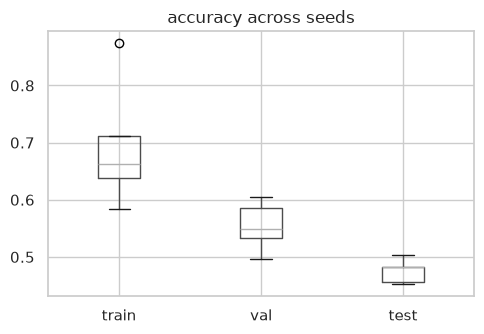

In [85]:
sweep = exp.run_seeds(data, seeds=[0, 1, 2, 3, 4])
display(sweep.groupby("split")[["accuracy", "balanced_acc", "f1_macro", "auc"]].agg(["mean", "std"]).round(3))
EvalPlots.seed_sweep(sweep, "accuracy")
sweep.to_csv(f"{cfg.output_dir}/seed_sweep_{cfg.rnn_type}.csv")